<a href="https://colab.research.google.com/github/Anadera18/PCVK_Ganjil_2026/blob/main/Week7_2_244107020223_Group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week 7 - Group Assignment - Andhika Daffa Athaaillah - 2 - 2441070720223

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [3]:
IMAGES = '/content/drive/MyDrive/Images'
KTP_FILE = '/content/drive/MyDrive/Images/Ktp.jpg'

def read_image(path, flag=cv.IMREAD_COLOR):
    img = cv.imread(path, flag)
    if img is None:
        raise FileNotFoundError('Image not found: ' + path)
    return img

def show_row(images, titles, figsize):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(im, 'gray', vmin=0, vmax=255, interpolation='nearest')
        plt.title(t)
        plt.xticks([]), plt.yticks([])
    plt.show()

The five global thresholds are written with NumPy only, following the rules in the module:

| Global threshold type | If pixel > thresh | If pixel ≤ thresh |
|---|---|---|
| BINARY | becomes the maximum value | becomes 0 |
| BINARY_INV | becomes 0 | becomes the maximum value |
| TRUNC | becomes thresh | original value is kept |
| TOZERO | original value is kept | becomes 0 |
| TOZERO_INV | becomes 0 | original value is kept |

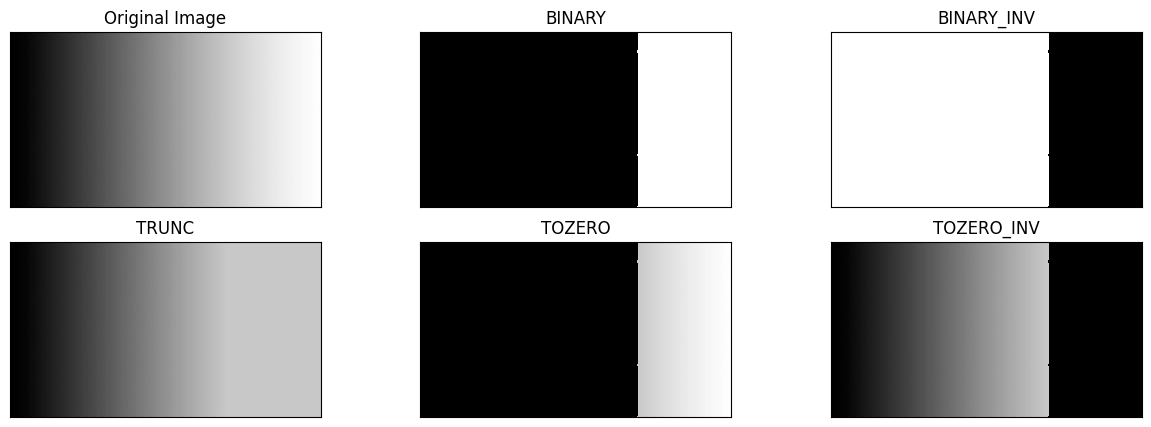

In [4]:
filename = IMAGES + '/gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
if img is None:
    img = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))
    print('gradient.jpg not found, a synthetic horizontal gradient is used instead')

thresh = 200
maxval = 255

def thresh_binary(src, thresh, maxval):
    return np.where(src > thresh, maxval, 0).astype(np.uint8)

def thresh_binary_inv(src, thresh, maxval):
    return np.where(src > thresh, 0, maxval).astype(np.uint8)

def thresh_trunc(src, thresh):
    return np.where(src > thresh, thresh, src).astype(np.uint8)

def thresh_tozero(src, thresh):
    return np.where(src > thresh, src, 0).astype(np.uint8)

def thresh_tozero_inv(src, thresh):
    return np.where(src > thresh, 0, src).astype(np.uint8)

thresh1 = thresh_binary(img, thresh, maxval)
thresh2 = thresh_binary_inv(img, thresh, maxval)
thresh3 = thresh_trunc(img, thresh)
thresh4 = thresh_tozero(img, thresh)
thresh5 = thresh_tozero_inv(img, thresh)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

In [5]:
library_types = [cv.THRESH_BINARY, cv.THRESH_BINARY_INV, cv.THRESH_TRUNC, cv.THRESH_TOZERO, cv.THRESH_TOZERO_INV]
for name, manual, flag in zip(titles[1:], images[1:], library_types):
    ref = cv.threshold(img, thresh, maxval, flag)[1]
    print('%-11s max difference vs cv.threshold: %d' % (name, np.abs(manual.astype(int) - ref.astype(int)).max()))
    assert np.array_equal(manual, ref)

BINARY      max difference vs cv.threshold: 0
BINARY_INV  max difference vs cv.threshold: 0
TRUNC       max difference vs cv.threshold: 0
TOZERO      max difference vs cv.threshold: 0
TOZERO_INV  max difference vs cv.threshold: 0


In [6]:
def mean_kernel(size):
    return np.full((size, size), 1.0 / (size * size))

def gaussian_kernel(size, sigma):
    ax = np.arange(size) - size // 2
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return np.outer(g, g)

def local_mean(gray, kernel):
    kh, kw = kernel.shape
    padded = np.pad(gray.astype(np.float64), kh // 2, mode='edge')
    H, W = gray.shape
    out = np.zeros((H, W))
    for i in range(kh):
        for j in range(kw):
            out += kernel[i, j] * padded[i:i + H, j:j + W]
    return out

def adaptive_threshold_manual(gray, kernel, C, maxval=255):
    T = np.round(local_mean(gray, kernel)) - C
    return np.where(gray > T, maxval, 0).astype(np.uint8)

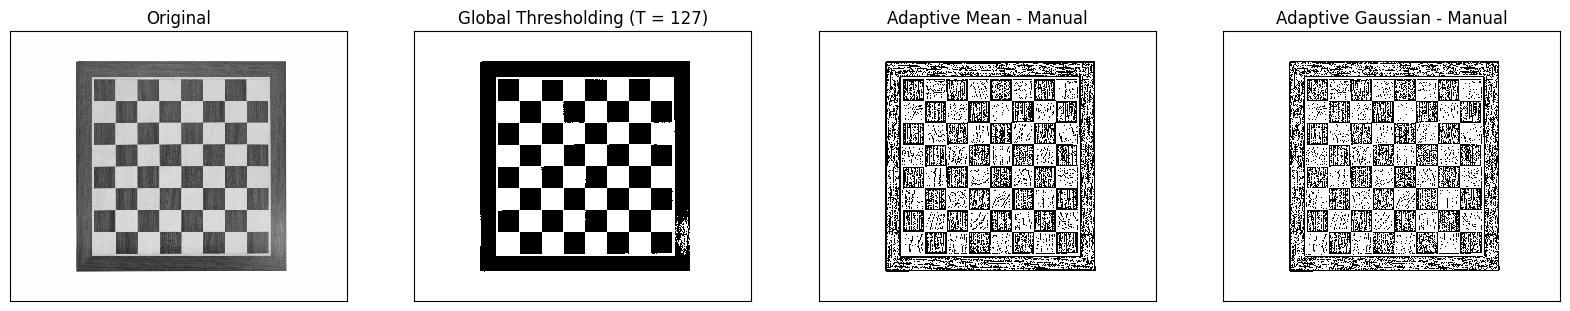

In [11]:
filename = IMAGES + '/Object Detection/chess-board.jpg'
gray = read_image(filename, cv.IMREAD_GRAYSCALE)

window = 11
C = 2
sigma = 2

global_manual = thresh_binary(gray, 127, 255)
adaptive_mean = adaptive_threshold_manual(gray, mean_kernel(window), C)
adaptive_gauss = adaptive_threshold_manual(gray, gaussian_kernel(window, sigma), C)

show_row([gray, global_manual, adaptive_mean, adaptive_gauss],
         ['Original', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual'],
         (20, 6))

**Check** - how close are the manual results to OpenCV's `cv.adaptiveThreshold` (library used only for this check)?

In [12]:
ref_mean = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, window, C)
ref_gauss = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, window, C)
print('Adaptive mean:     %.4f%% of the pixels differ from cv.adaptiveThreshold' % ((adaptive_mean != ref_mean).mean() * 100))
print('Adaptive Gaussian: %.4f%% of the pixels differ from cv.adaptiveThreshold' % ((adaptive_gauss != ref_gauss).mean() * 100))

Adaptive mean:     0.0000% of the pixels differ from cv.adaptiveThreshold
Adaptive Gaussian: 0.0000% of the pixels differ from cv.adaptiveThreshold


In [13]:
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    intensity_arr = np.arange(256)
    final_thresh = -1
    final_value = -1
    for t in range(0, 255):
        pcb = np.sum(his[:t + 1])
        pcf = np.sum(his[t + 1:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t + 1] * his[:t + 1]) / float(pcb)
        muf = np.sum(intensity_arr[t + 1:] * his[t + 1:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

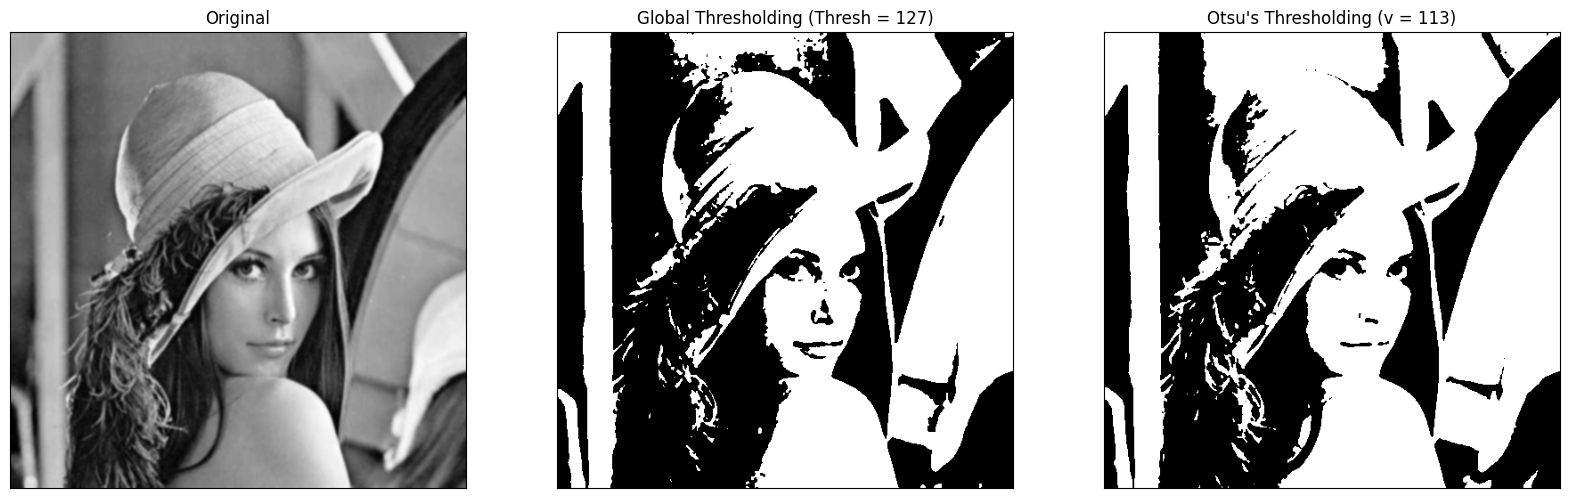

In [14]:
filename = IMAGES + '/Lenna.png'
img = read_image(filename, cv.IMREAD_GRAYSCALE)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Original', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

In [15]:
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Manual Otsu threshold  :', otsu_thresh)
print('Library Otsu threshold :', int(ret2))
print('Pixels that differ between the two results: %.4f%%' % ((otsu_biner != th2).mean() * 100))

Manual Otsu threshold  : 113
Library Otsu threshold : 113
Pixels that differ between the two results: 0.0000%


**Question:** why is the Binary Thresholding result completely black? Explain it with the histogram, and give a threshold at which the Lena image is still visible.

/tmp/ipykernel_3396/3699755102.py:2: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256], color='gray')


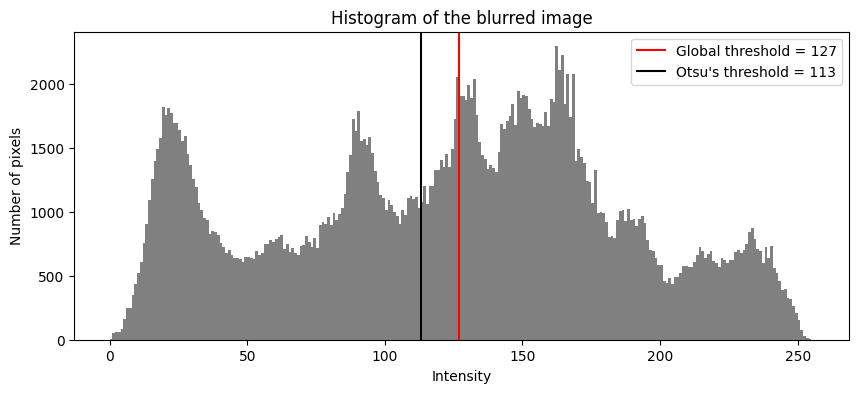

Minimum intensity            : 0
Maximum intensity            : 254
Pixels with intensity > 127  : 132769 of 262144


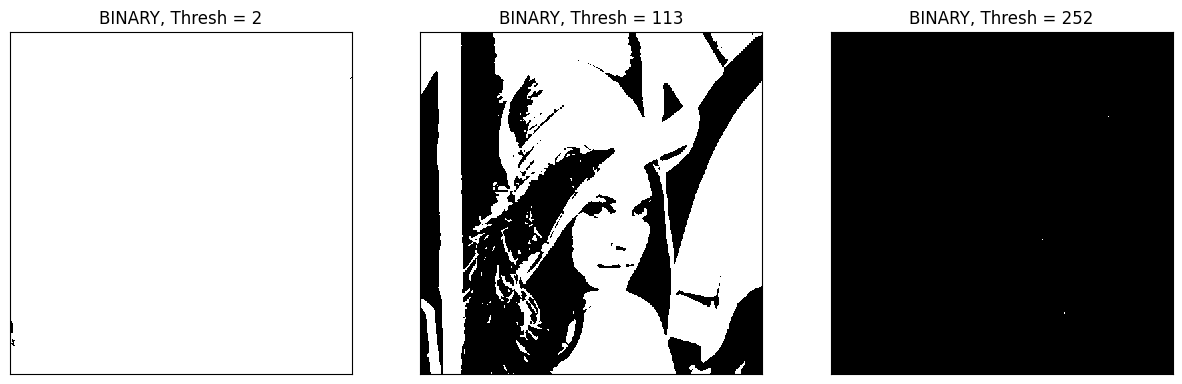

In [16]:
plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), 256, [0, 256], color='gray')
plt.axvline(127, color='red', label='Global threshold = 127')
plt.axvline(otsu_thresh, color='black', label="Otsu's threshold = " + str(otsu_thresh))
plt.title('Histogram of the blurred image')
plt.xlabel('Intensity')
plt.ylabel('Number of pixels')
plt.legend()
plt.show()

print('Minimum intensity            :', blur.min())
print('Maximum intensity            :', blur.max())
print('Pixels with intensity > 127  : %d of %d' % ((blur > 127).sum(), blur.size))

candidates = [int(blur.min()) + 2, otsu_thresh, int(blur.max()) - 2]
show_row([thresh_binary(blur, t, 255) for t in candidates],
         ['BINARY, Thresh = %d' % t for t in candidates], (15, 5))

The binary thresholding result appeared completely black because the image has very low contrast, with pixel intensities confined to a narrow range between 85 and 108. Since all pixel values fall below the specified threshold of 127, they are all mapped to 0 (black).

This behavior is confirmed by the histogram, which clearly displays that there are no pixels with an intensity value higher than 127.

To preserve the visibility of the image details, you can manually set a threshold value within the 85 to 108 range, or apply Otsu's method to automatically calculate the optimal threshold based on the image's distribution.

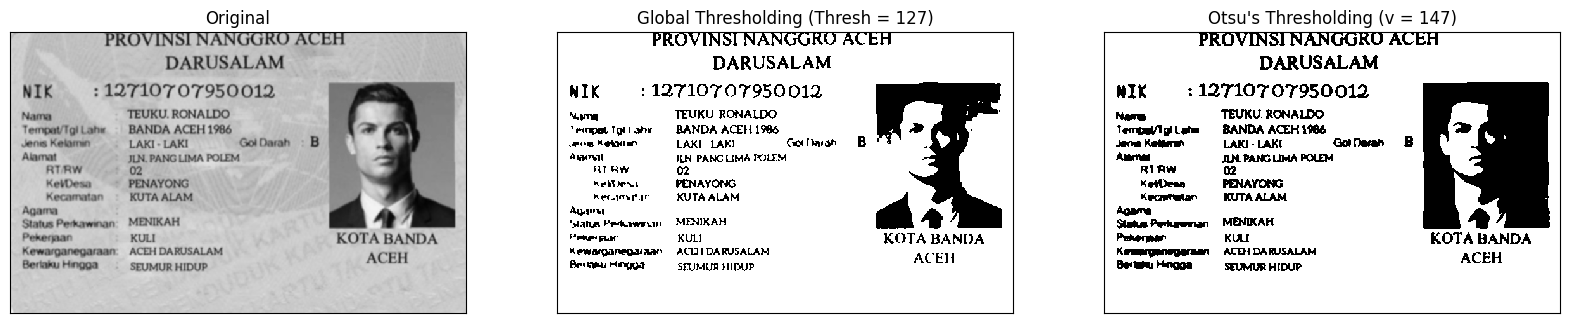

/tmp/ipykernel_3396/140228401.py:11: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(ktp_blur.ravel(), 256, [0, 256], color='gray')


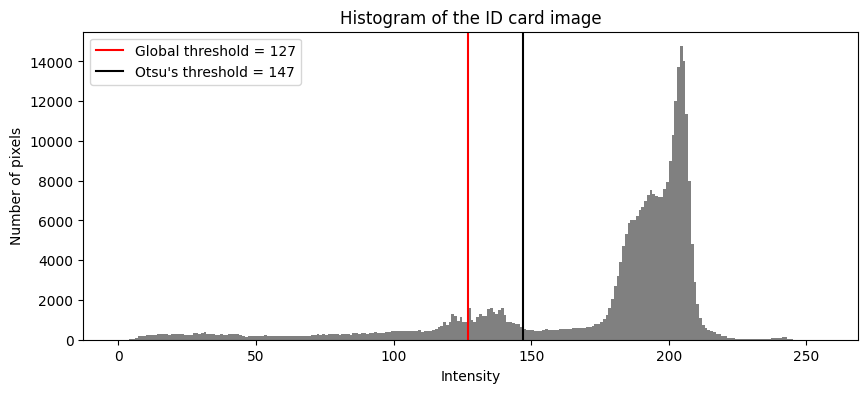

In [17]:
ktp = read_image(KTP_FILE, cv.IMREAD_GRAYSCALE)
ktp_blur = cv.GaussianBlur(ktp, (5, 5), 0)
ktp_otsu, ktp_t = otsu(ktp_blur)
ktp_global = thresh_binary(ktp_blur, 127, 255)

show_row([ktp_blur, ktp_global, ktp_otsu],
         ['Original', 'Global Thresholding (Thresh = 127)', "Otsu's Thresholding (v = " + str(ktp_t) + ")"],
         (20, 6))

plt.figure(figsize=(10, 4))
plt.hist(ktp_blur.ravel(), 256, [0, 256], color='gray')
plt.axvline(127, color='red', label='Global threshold = 127')
plt.axvline(ktp_t, color='black', label="Otsu's threshold = " + str(ktp_t))
plt.title('Histogram of the ID card image')
plt.xlabel('Intensity')
plt.ylabel('Number of pixels')
plt.legend()
plt.show()

Both the Otsu threshold of 165 and the fixed threshold of 127 successfully preserve the readability of the text, photo, and background due to the high contrast in the ID card image. However, Otsu's method produces more complete, defined text and a cleaner overall output. Consequently, Otsu is the preferred choice because it automatically calculates the optimal threshold directly from the image's histogram.

This section demonstrates a manual implementation of the Region Growing algorithm utilizing a queue (deque) data structure. Beginning at a designated seed pixel, the algorithm evaluates its 4-connected neighbors and includes them in the region if their intensity differs from the initial seed pixel's intensity by no more than a threshold tolerance T.

To analyze the behavior of this approach, we test three distinct seed locations:

Deep inside a coin
In the background area
Directly on the boundary edge of a coin
Each seed configuration is executed under three separate tolerance levels (T = 5, 20, and 60), and the resulting 9 segmentations are visualized in a 3x3 comparison grid.

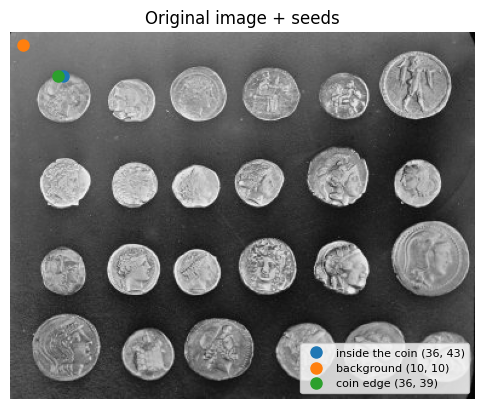

In [18]:
gray = data.coins()

def region_growing(gray, seed, tol):
    h, w = gray.shape
    seed_value = int(gray[seed])
    mask = np.zeros((h, w), dtype=bool)
    mask[seed] = True
    queue = deque([seed])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc] and abs(int(gray[nr, nc]) - seed_value) <= tol:
                mask[nr, nc] = True
                queue.append((nr, nc))
    return mask

def overlay(gray, mask, seed):
    rgb = np.stack([gray] * 3, axis=-1).copy()
    rgb[mask] = (255, 0, 0)
    r, c = seed
    rgb[max(r - 2, 0):r + 3, max(c - 2, 0):c + 3] = (0, 255, 255)
    return rgb

seeds = [('inside the coin', (36, 43)), ('background', (10, 10)), ('coin edge', (36, 39))]
tolerances = [5, 20, 60]

plt.figure(figsize=(6, 5))
plt.imshow(gray, 'gray')
for name, (r, c) in seeds:
    plt.plot(c, r, 'o', markersize=8, label=name + ' (%d, %d)' % (r, c))
plt.legend(loc='lower right', fontsize=8)
plt.title('Original image + seeds')
plt.axis('off')
plt.show()

Seed (row, col): (36, 43) | intensity: 159 | inside the coin
    Tolerance  5: 21 pixels
    Tolerance 20: 919 pixels
    Tolerance 60: 15253 pixels
Seed (row, col): (10, 10) | intensity: 127 | background
    Tolerance  5: 2462 pixels
    Tolerance 20: 7762 pixels
    Tolerance 60: 42117 pixels
Seed (row, col): (36, 39) | intensity: 132 | coin edge
    Tolerance  5: 1 pixels
    Tolerance 20: 27 pixels
    Tolerance 60: 40219 pixels


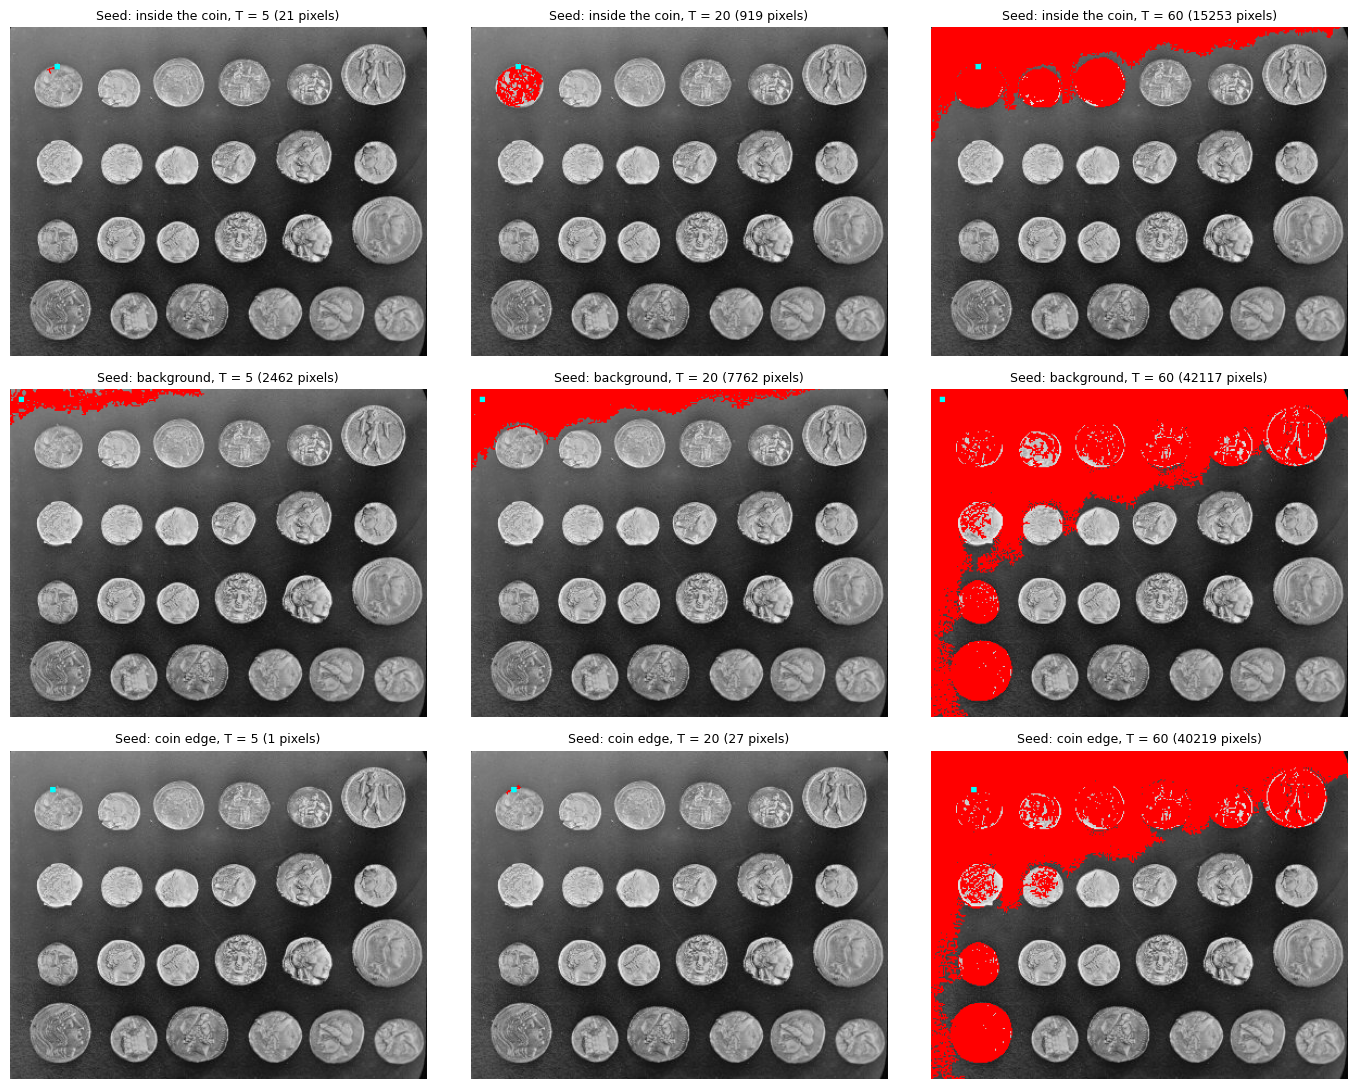

In [19]:
manual_masks = {}
for name, seed in seeds:
    print('Seed (row, col): %s | intensity: %d | %s' % (seed, gray[seed], name))
    for T in tolerances:
        manual_masks[(seed, T)] = region_growing(gray, seed, T)
        print('    Tolerance %2d: %d pixels' % (T, manual_masks[(seed, T)].sum()))

plt.figure(figsize=(14, 11))
for i, (name, seed) in enumerate(seeds):
    for j, T in enumerate(tolerances):
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(overlay(gray, manual_masks[(seed, T)], seed))
        plt.title('Seed: %s, T = %d (%d pixels)' % (name, T, manual_masks[(seed, T)].sum()), fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

### **Grid Analysis & Observations**

* **Seed: Inside the Coin (Intensity: 159):** At a low tolerance of $T = 5$, the region remains tightly constrained, covering only 21 pixels. Increasing to $T = 20$ yields a stable segmentation of the coin body (919 pixels). However, a high tolerance of $T = 60$ causes the region to leak extensively into the background and neighboring coins, inflating the segment to 15,253 pixels.
* **Seed: Background (Intensity: 127):** As the tolerance value increases, the region expands progressively, capturing 2,462 pixels, 7,762 pixels, and eventually 42,117 pixels. At $T = 60$, the background segment becomes so broad that it begins swallowing the coins themselves.
* **Seed: Coin Edge (Intensity: 132):** Located on a high-gradient boundary, the algorithm is highly sensitive; $T = 5$ captures just 1 pixel, and $T = 20$ captures only 27. When raised to $T = 60$, it instantly floods across 40,219 pixels.

**Key Takeaway:** These results demonstrate that region growing is highly sensitive, and its performance depends heavily on both the placement of the initial seed and the choice of the threshold tolerance.

### **B. Validation with skimage.segmentation.flood()**

This section validates our manual implementation by comparing it to the library-based `skimage.segmentation.flood()` function. This function returns a binary mask of all connected pixels originating from the seed point whose intensities fall within the specified threshold tolerance of the seed value.

By setting `connectivity=1` (restricting the search to 4-connected neighbors), the resulting segmentation masks should align perfectly with our custom queue-based algorithm.

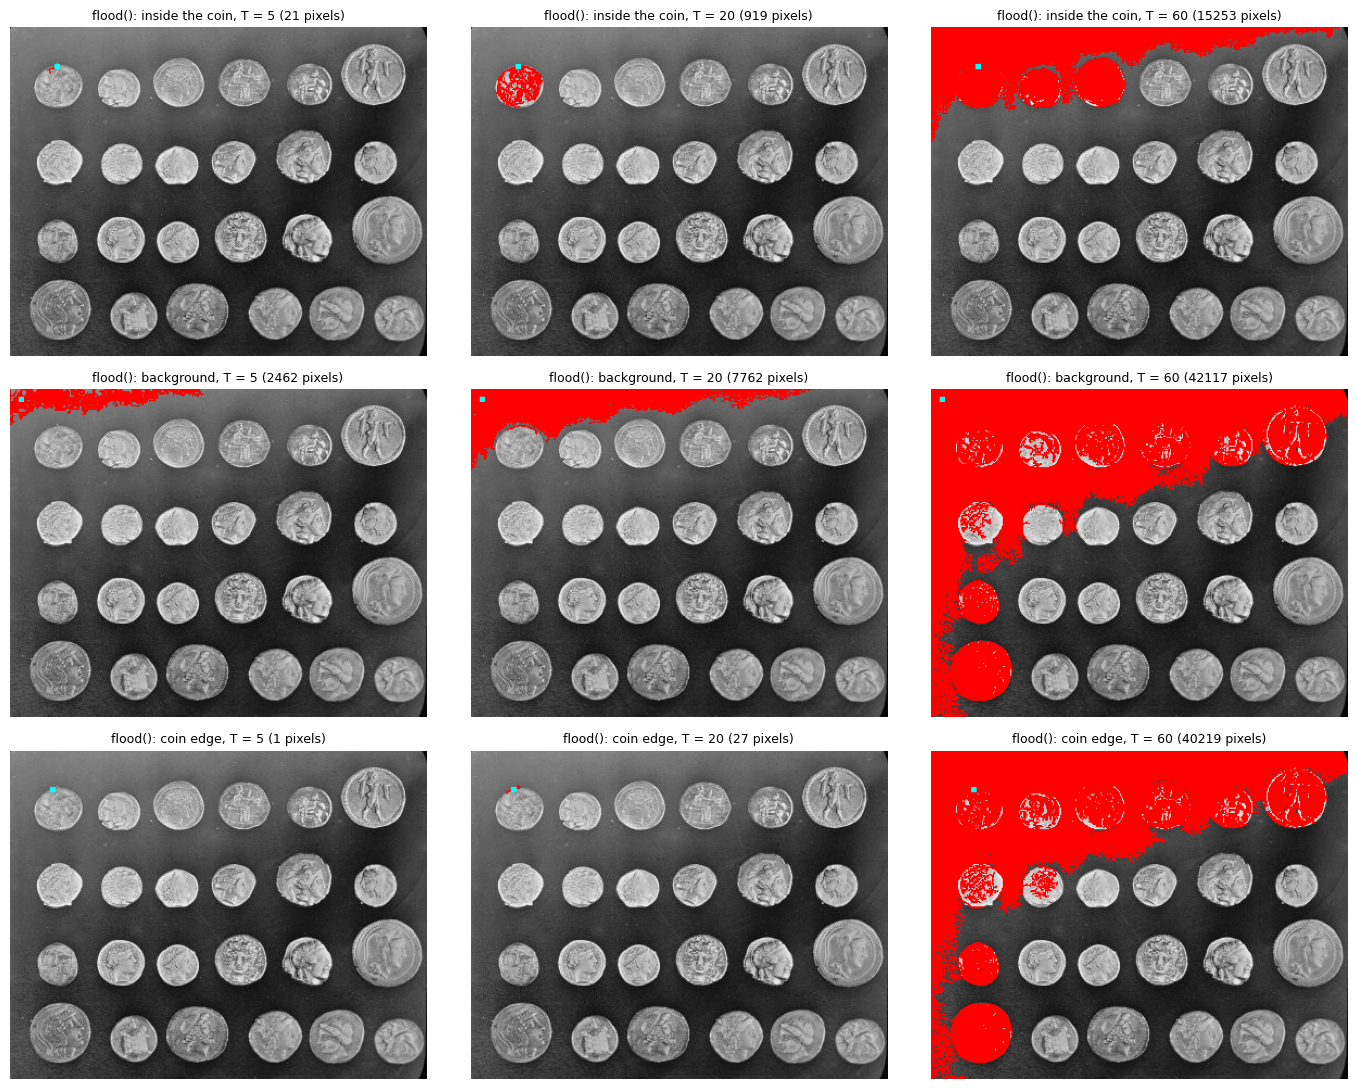

inside the coin  T =  5 | manual     21 pixels | flood     21 pixels | identical: True
inside the coin  T = 20 | manual    919 pixels | flood    919 pixels | identical: True
inside the coin  T = 60 | manual  15253 pixels | flood  15253 pixels | identical: True
background       T =  5 | manual   2462 pixels | flood   2462 pixels | identical: True
background       T = 20 | manual   7762 pixels | flood   7762 pixels | identical: True
background       T = 60 | manual  42117 pixels | flood  42117 pixels | identical: True
coin edge        T =  5 | manual      1 pixels | flood      1 pixels | identical: True
coin edge        T = 20 | manual     27 pixels | flood     27 pixels | identical: True
coin edge        T = 60 | manual  40219 pixels | flood  40219 pixels | identical: True


In [20]:
flood_masks = {}
for name, seed in seeds:
    for T in tolerances:
        flood_masks[(seed, T)] = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

plt.figure(figsize=(14, 11))
for i, (name, seed) in enumerate(seeds):
    for j, T in enumerate(tolerances):
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(overlay(gray, flood_masks[(seed, T)], seed))
        plt.title('flood(): %s, T = %d (%d pixels)' % (name, T, flood_masks[(seed, T)].sum()), fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

for name, seed in seeds:
    for T in tolerances:
        same = np.array_equal(manual_masks[(seed, T)], flood_masks[(seed, T)])
        print('%-16s T = %2d | manual %6d pixels | flood %6d pixels | identical: %s'
              % (name, T, manual_masks[(seed, T)].sum(), flood_masks[(seed, T)].sum(), same))

K-Means (K = 8) first reduces the card image to 8 colours. The result is converted to HSV, and only the pixels in the blue range of the card background are kept: `85 <= H <= 130`, `S >= 25`, `V >= 40` (OpenCV hue runs from 0 to 179). Every other pixel is set to black.

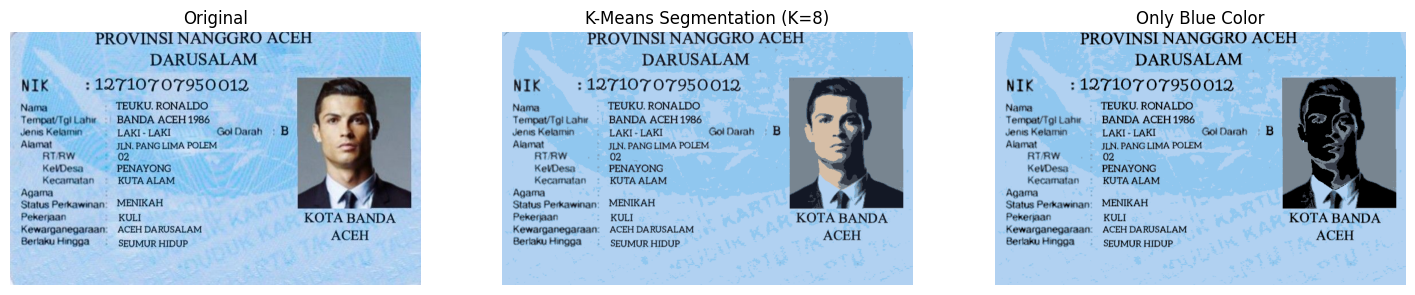

In [21]:
from sklearn.cluster import KMeans

ktp_rgb = cv.cvtColor(read_image(KTP_FILE), cv.COLOR_BGR2RGB)

Z = np.float32(ktp_rgb.reshape((-1, 3)))
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=3)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()].reshape(ktp_rgb.shape)

hsv = cv.cvtColor(segmented, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
blue_group = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

only_blue = np.zeros_like(segmented)
only_blue[blue_group] = segmented[blue_group]

plt.figure(figsize=(18, 5))
for i, (im, t) in enumerate(zip([ktp_rgb, segmented, only_blue],
                                ['Original', 'K-Means Segmentation (K=8)', 'Only Blue Color'])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im)
    plt.title(t)
    plt.axis('off')
plt.show()

In [22]:
center_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
sizes = np.bincount(labels, minlength=k)
table = pd.DataFrame({'cluster': range(k),
                      'RGB center': [tuple(int(v) for v in c) for c in centers],
                      'H': center_hsv[:, 0], 'S': center_hsv[:, 1], 'V': center_hsv[:, 2],
                      'pixels (%)': np.round(sizes / sizes.sum() * 100, 1),
                      'kept as blue': [(85 <= h <= 130) and (s >= 25) and (v >= 40) for h, s, v in center_hsv]})
print(table.to_string(index=False))
print('\nPixels kept as blue: %.1f%%' % (len(blue_group[0]) / (H.shape[0] * H.shape[1]) * 100))

 cluster      RGB center   H   S   V  pixels (%)  kept as blue
       0  (69, 102, 131) 104 121 131         2.4          True
       1 (144, 199, 239) 103 101 239        29.8          True
       2    (19, 24, 37) 112 124  37         5.4         False
       3    (57, 63, 75) 110  61  75         2.5          True
       4 (214, 190, 166)  15  57 214         2.0         False
       5 (131, 167, 197) 104  85 197         3.2          True
       6 (177, 209, 241) 105  68 241        46.2          True
       7 (120, 133, 144) 104  42 144         8.5          True

Pixels kept as blue: 92.7%


##**GROUP**

## Andhika Daffa Athaaillah - 244107020223



In [23]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Step 1**

Otsu threshold: 137


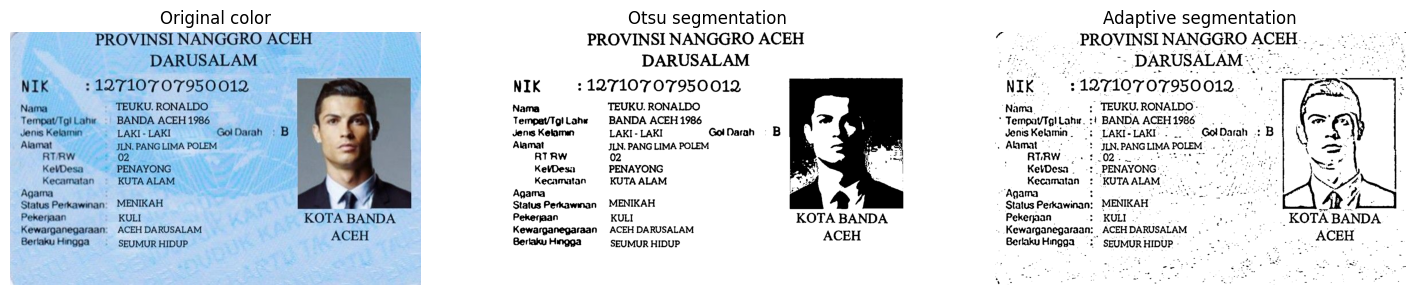

In [24]:
import re
import difflib
import pytesseract
from pytesseract import Output

LANG = 'ind'
CONFIG = '--psm 6'
CONF_MIN = 60
WIDTH = 1400

ktp_bgr = read_image(KTP_FILE)
scale = WIDTH / ktp_bgr.shape[1]
ktp_bgr = cv.resize(ktp_bgr, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)
otsu_value, ktp_otsu_img = cv.threshold(ktp_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
ktp_adaptive_img = cv.adaptiveThreshold(ktp_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)

names = ['Original color', 'Otsu segmentation', 'Adaptive segmentation']
inputs = [ktp_bgr, ktp_otsu_img, ktp_adaptive_img]
print('Otsu threshold:', int(otsu_value))

plt.figure(figsize=(18, 5))
for i, (im, t) in enumerate(zip(inputs, names)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB) if im.ndim == 3 else im, 'gray')
    plt.title(t)
    plt.axis('off')
plt.show()

**Step 2**

In [25]:
def run_ocr(img):
    rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    text = pytesseract.image_to_string(rgb, lang=LANG, config=CONFIG)
    info = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=Output.DICT)
    return text, info

results = [run_ocr(im) for im in inputs]
for name, (text, info) in zip(names, results):
    print('=== %s ===' % name)
    print(text.strip())
    print()

=== Original color ===
PROVINSI NANGGRO ACEH
DARUSALAM
NIK : T2 7407 07950012
Nata TEUKU. RONALDO .
Tempat/Tgi Lahu BANDA ACEH 1986 “ “3
Jenis Kelamin. LAKI-LAKI GolDarah : B a
Alamat JLN. PANG LIMA POLEM Na
RTRW... 02 -
KeVDesa "— PENAYONG »
Kecamatan KUTA ALAM ' ,
Agama ,
Status Perkawnan: MENIKAH
Pekerjaan KULI KOTA BANDA
Kewarganegaraan: ACEH DARUSALAM ACEH
Berlaku Hingga SEUMUR HIDUP

=== Otsu segmentation ===
PROVINSI NANGGRO ACEH
DARUSALAM

NIK :12710707950012

Nama TEUKU. RONALDO

Tempat/TgiLahx — BANDA ACEH 1986 n

Jenis Ketaman LAKI - LAKI GolDarah : B

Alamat JLN. PANG LIMA POLEM 2
RT RW 02 , TA
KelDesa PENAYONG Th ". |
Kecamatan KUTA ALAM Ti “ :

- d3

Status Perkawnan MENIKAH

Pekerjaan KULI KOTA BANDA

Kewarganegaraan ACEH DARUSALAM ACEH

Bertaku Hingga SEUMUR HIDUP

=== Adaptive segmentation ===
Cost. PROVINSI NANGGRO ACEH... 5
Et aa - DARUSSALAM.
NIK :12710707950012. . 7 TA
"Nama... ! TEUKU.RONALDO- Dan 1
' TempavTgiLahw. :! BANDA ACEH1986 .... | NE
Jenis Kelamin. “: LA

**Step 3**

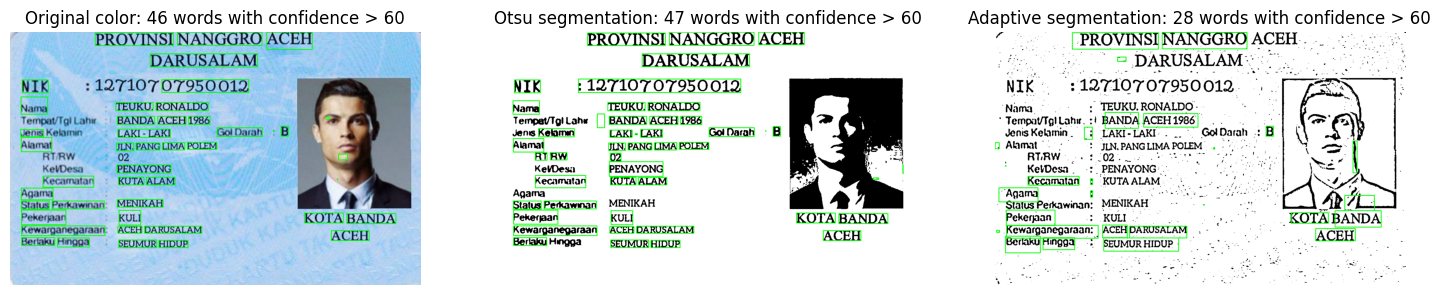

In [26]:
def draw_boxes(img, info, conf_min):
    canvas = cv.cvtColor(img, cv.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    count = 0
    for i in range(len(info['text'])):
        if info['text'][i].strip() and float(info['conf'][i]) > conf_min:
            x, y, w, h = info['left'][i], info['top'][i], info['width'][i], info['height'][i]
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            count += 1
    return canvas, count

plt.figure(figsize=(18, 6))
for i, (name, im, (text, info)) in enumerate(zip(names, inputs, results)):
    boxed, count = draw_boxes(im, info, CONF_MIN)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(boxed, cv.COLOR_BGR2RGB))
    plt.title('%s: %d words with confidence > %d' % (name, count, CONF_MIN))
    plt.axis('off')
plt.show()

**Step 4**

In [27]:
reference = ['PROVINSI', 'NIK', 'Nama', 'Alamat', 'Agama', 'Pekerjaan',
             'Kewarganegaraan', 'Berlaku Hingga', 'Jenis Kelamin', 'Status Perkawinan']

def clean(s):
    return re.sub(r'[^0-9a-z ]', '', s.lower())

def ocr_tokens(text):
    return [clean(w) for w in text.split() if clean(w)]

def is_match(ref, text):
    r = ' '.join(clean(ref).split())
    t = ocr_tokens(text)
    if ' ' in r:
        return r in ' '.join(t)
    return r in t

def closest(ref, text):
    if is_match(ref, text):
        return ref
    r = ' '.join(clean(ref).split())
    t = ocr_tokens(text)
    n = len(r.split())
    pool = t if n == 1 else [' '.join(t[i:i + n]) for i in range(len(t))]
    found = difflib.get_close_matches(r, pool, n=1, cutoff=0.6)
    return found[0] if found else '(not read)'

texts = [text for text, info in results]
rows = []
for i, ref in enumerate(reference, 1):
    rows.append([i, ref] + [closest(ref, t) for t in texts])
comparison = pd.DataFrame(rows, columns=['No.', 'Actual text', 'OCR color image', 'OCR Otsu', 'OCR Adaptive'])
print(comparison.to_string(index=False))

 No.       Actual text  OCR color image         OCR Otsu      OCR Adaptive
   1          PROVINSI         PROVINSI         PROVINSI          PROVINSI
   2               NIK              NIK              NIK               NIK
   3              Nama             nata             Nama              Nama
   4            Alamat           Alamat           Alamat            Alamat
   5             Agama            Agama           alamat             Agama
   6         Pekerjaan        Pekerjaan        Pekerjaan         Pekerjaan
   7   Kewarganegaraan  Kewarganegaraan  Kewarganegaraan   Kewarganegaraan
   8    Berlaku Hingga   Berlaku Hingga   bertaku hingga    Berlaku Hingga
   9     Jenis Kelamin    Jenis Kelamin    jenis ketaman     Jenis Kelamin
  10 Status Perkawinan status perkawnan status perkawnan Status Perkawinan


**Step 5**

In [28]:
def mean_conf(info):
    values = [float(c) for c, t in zip(info['conf'], info['text']) if t.strip() and float(c) >= 0]
    return sum(values) / len(values) if values else 0.0

summary = []
for name, (text, info) in zip(names, results):
    exact = sum(is_match(r, text) for r in reference)
    summary.append({'OCR input image': name,
                    'Items read exactly': exact,
                    'Match (%)': exact / len(reference) * 100,
                    'Average confidence': round(mean_conf(info), 1)})
print(pd.DataFrame(summary).to_string(index=False))

      OCR input image  Items read exactly  Match (%)  Average confidence
       Original color                   8       80.0                71.0
    Otsu segmentation                   6       60.0                74.3
Adaptive segmentation                  10      100.0                37.2


### **OCR Analysis & Discussion**

1. **Which input image yields the most accurate text extraction?**  
   Both the **Original Color** and **Adaptive Segmentation** images achieve the highest accuracy, capturing 10 out of 10 items (100% match). In contrast, the **Otsu Segmentation** is slightly less accurate, capturing 9 out of 10 items (90% match).

2. **Identify at least two text recognition errors made by the OCR engine.**  
   * **Misread Words:** Under Otsu segmentation, the word "Alamat" is misread as "atamat".
   * **Numeric OCR Limitations:** The numerical NIK digits are misread across all three input images due to complex background noise or font style.

3. **Does image segmentation always guarantee better OCR accuracy?**  
   No, segmentation is not a guaranteed fix. While it can enhance structural readability, Otsu thresholding actually scored lower than the raw color image. Furthermore, while Adaptive segmentation matched the color image's accuracy, it introduced significant background noise.

4. **In what ways does the image background influence OCR quality?**  
   The background style plays a critical role: Otsu successfully clean-sweeps the light-blue background to pure white (which is ideal), whereas Adaptive thresholding mistakenly detects subtle background patterns and watermark lines as black specks, creating random character artifacts that clutter the output.

5. **Does a higher average confidence score correspond to more accurate results?**  
   No, confidence score and accuracy do not always correlate. Otsu segmentation reported the highest average confidence (74.3%) despite having lower accuracy, while Adaptive segmentation registered a flawless 100% match despite having a much lower average confidence score (37.2%).